# FastV Paper Reproduction Suite (Modern Transformers & Colab Compatible)

Reproduction of **"An Image is Worth 1/2 Tokens After Layer 2: Plug-and-Play Inference Acceleration for Large Vision-Language Models"** (Chen et al., ECCV 2024 Oral, [arXiv:2403.06764](https://arxiv.org/abs/2403.06764)).

### Modernization Highlights
* **Upstream `transformers` (>=4.45 through 5.x) native**: Uses our hook-based `FastVController` (`src/FastV/fastv_hf.py`) directly on upstream HuggingFace `LlavaForConditionalGeneration`, eliminating the legacy vendored `transformers 4.31 / 4.39` forks and all Colab pip dependency conflicts.
* **Single model load across all experiments**: Loads LLaVA-1.5 once in GPU memory (supporting 4-bit NF4, 8-bit, or FP16) and dynamically switches FastV `(K, R, mode)` between runs.
* **Complete Paper Coverage**:
  1. **Section 1 — Theoretical FLOPs Analysis** (Section 3.3, Equations 1–2 & Figure 1)
  2. **Section 2 — Qualitative & KV-Cache Acceleration Demo** (Vanilla vs FastV, `use_cache=True` & `False`)
  3. **Section 3 — Experiment 1: Inefficient Visual Attention Visualization** (Section 2, Figures 2 & 3)
  4. **Section 4 — Experiment 2: A-OKVQA Accuracy, Latency & Peak GPU Memory** (Table 4 & README Latency Table)
  5. **Section 5 — Experiment 3: OCR-VQA Hyperparameter Ablation over $K$ and $R$** (Figure 7, including $K=0$ random baseline)
  6. **Section 6 — Experiment 4: Multi-Benchmark Evaluation — MME (Table 3), MMMU & Captioning (Table 1) + Optional `lmms-eval`**
  7. **Section 7 — Consolidated Paper Reproduction Dashboard & Standalone CLI Verification**

> **Tip**: Set `RUN_MODE = "fast"` (default) for a ~10–15 minute end-to-end Colab L4/T4 verification run, or `RUN_MODE = "full"` to evaluate the full dataset splits matching the paper.

## Section 0 — Hardware, Repository Sync & Conflict-Free Environment Setup

In [7]:
!nvidia-smi
import platform, sys
print(f"Python: {sys.version} | Platform: {platform.platform()}")

Sun Nov 22 23:54:38 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   46C    P8             17W /   72W |       3MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [8]:
import os
import subprocess

REPO_URL = "https://github.com/vlsmcin/FastV-adaptation.git"
BRANCH = "colab-execution-test"

if os.path.isdir("/content"):
    repo_dir = "/content/FastV-adaptation"
    if os.path.isdir(os.path.join(repo_dir, ".git")):
        os.chdir(repo_dir)
        subprocess.run(["git", "fetch", "origin"], check=True)
        subprocess.run(["git", "switch", BRANCH], check=True)
        subprocess.run(["git", "pull", "--ff-only", "origin", BRANCH], check=True)
    else:
        os.chdir("/content")
        subprocess.run(["git", "clone", "--branch", BRANCH, "--single-branch", REPO_URL], check=True)
        os.chdir(repo_dir)
else:
    # Local Jupyter execution inside existing checkout
    repo_dir = os.getcwd()

print("Working directory:", os.getcwd())

Working directory: /content/FastV-adaptation


In [9]:
# Conflict-free dependency installation:
# Keeps Colab's preinstalled torch/transformers/huggingface-hub/tokenizers intact
# (only upgrading transformers if older than 4.45) and installs missing runtime packages.
import importlib
import subprocess
import sys


def _pkg_version(name: str):
    try:
        from importlib.metadata import version
        return version(name)
    except Exception:
        return None


pkgs_to_install = []
tf_ver = _pkg_version("transformers")
if tf_ver is None:
    pkgs_to_install.append("transformers>=4.45.0")
else:
    major_minor = tuple(int(x) for x in tf_ver.split(".")[:2] if x.isdigit())
    if major_minor < (4, 45):
        pkgs_to_install.append("transformers>=4.45.0")

for pkg, spec in [
    ("accelerate", "accelerate>=0.34.0"),
    ("bitsandbytes", "bitsandbytes>=0.44.0"),
    ("datasets", "datasets>=2.20.0"),
    ("einops", "einops>=0.8.0"),
    ("sentencepiece", "sentencepiece>=0.2.0"),
    ("seaborn", "seaborn>=0.13.0"),
    ("pandas", "pandas>=2.1.0"),
    ("matplotlib", "matplotlib>=3.8.0"),
    ("PIL", "Pillow>=10.0.0"),
    ("requests", "requests>=2.31.0"),
    ("tqdm", "tqdm>=4.66.0"),
]:
    try:
        importlib.import_module(pkg)
    except ImportError:
        pkgs_to_install.append(spec)

if pkgs_to_install:
    print("Installing missing/outdated packages:", pkgs_to_install)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs_to_install], check=True)
else:
    print("All required modern packages are already installed!")

import torch, transformers, accelerate, datasets
print(
    f"torch={torch.__version__} (CUDA={torch.cuda.is_available()}) | "
    f"transformers={transformers.__version__} | "
    f"accelerate={accelerate.__version__} | "
    f"datasets={datasets.__version__}"
)

All required modern packages are already installed!
torch=2.14.1+cu130 (CUDA=True) | transformers=5.22.1 | accelerate=1.15.0 | datasets=4.8.5


In [10]:
# Verify our modern hook-based FastV module passes all unit tests (both v4 & v5 layouts)
!python -m unittest tests/test_fastv_hf.py -v

test_fastv_hf (unittest.loader._FailedTest.test_fastv_hf) ... ERROR

ERROR: test_fastv_hf (unittest.loader._FailedTest.test_fastv_hf)
----------------------------------------------------------------------
ImportError: Failed to import test module: test_fastv_hf
Traceback (most recent call last):
  File "/usr/lib/python3.13/unittest/loader.py", line 141, in loadTestsFromName
    module = __import__(module_name)
ModuleNotFoundError: No module named 'tests.test_fastv_hf'


----------------------------------------------------------------------
Ran 1 test in 0.000s

FAILED (errors=1)


In [11]:
# ==============================================================================
# Global Experiment Configuration
# ==============================================================================
import json
import os
import sys
import time
from io import BytesIO

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import torch
from IPython.display import Image as IPyImage, display
from PIL import Image
from tqdm.auto import tqdm

REPO_ROOT = os.getcwd()
SRC_DIR = os.path.join(REPO_ROOT, "src")
if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)

from FastV.fastv_hf import (
    FastVConfig,
    compute_fastv_flops_ratio,
    compute_layer_attention_efficiency,
    compute_rouge_l,
    load_llava_model,
    prepare_llava_inputs,
    resolve_hf_model_id,
)

# Choose "fast" (~10-15 min on Colab L4) or "full" (complete paper dataset sizes)
RUN_MODE = os.environ.get("FASTV_RUN_MODE", "fast").lower()

# Model & quantization settings
# "auto" picks 13B on >=24 GiB GPUs (A100/RTX 3090/4090) and 7B on L4 (22 GiB) / T4 (15 GiB)
MODEL_SIZE = os.environ.get("FASTV_MODEL_SIZE", "7b")
QUANTIZATION = os.environ.get("FASTV_QUANTIZATION", "4bit")  # "4bit", "8bit", or "none" (fp16)

# Optional full lmms-eval harness run in Section 6B
RUN_LMMS_EVAL = False

OUTPUT_ROOT = os.path.join(REPO_ROOT, "reproduction_results")
os.makedirs(OUTPUT_ROOT, exist_ok=True)

if RUN_MODE == "full":
    AOKVQA_MAX_SAMPLES = None      # All 1,145 validation samples
    OCRVQA_MAX_EXAMPLES = 500      # Paper uses first 500 test images
    OCRVQA_MAX_QUESTIONS = None
    OCRVQA_KS = [0, 1, 2, 3, 5, 10]
    OCRVQA_RS = [0.0, 0.25, 0.50, 0.75, 0.875]
    MME_MAX_PER_SUBTASK = None     # All MME samples
    MMMU_MAX_SAMPLES = 150
    CAPTION_MAX_SAMPLES = 100
else:
    AOKVQA_MAX_SAMPLES = 100       # Fast Colab subset (set RUN_MODE="full" for all 1,145)
    OCRVQA_MAX_EXAMPLES = 40
    OCRVQA_MAX_QUESTIONS = 60
    OCRVQA_KS = [0, 1, 2, 3, 5]
    OCRVQA_RS = [0.0, 0.25, 0.50, 0.75, 0.875]
    MME_MAX_PER_SUBTASK = 12       # 6 image pairs x 2 questions per MME subtask
    MMMU_MAX_SAMPLES = 40
    CAPTION_MAX_SAMPLES = 25

GPU_MEM_GIB = (
    torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    if torch.cuda.is_available()
    else 0.0
)
MODEL_ID = resolve_hf_model_id(requested_size=MODEL_SIZE, gpu_memory_gib=GPU_MEM_GIB)
DTYPE = torch.float16 if torch.cuda.is_available() else torch.float32

print(f"RUN_MODE       : {RUN_MODE}")
print(f"MODEL_ID       : {MODEL_ID}")
print(f"QUANTIZATION   : {QUANTIZATION}")
print(f"GPU VRAM       : {GPU_MEM_GIB:.2f} GiB")
print(f"OUTPUT_ROOT    : {OUTPUT_ROOT}")

RUN_MODE       : fast
MODEL_ID       : llava-hf/llava-1.5-7b-hf
QUANTIZATION   : 4bit
GPU VRAM       : 22.03 GiB
OUTPUT_ROOT    : /content/FastV-adaptation/reproduction_results


---
## Section 1 — Theoretical FLOPs Analysis (Paper Section 3.3, Equations 1–2 & Figure 1)

In the FastV paper, the per-layer Transformer FLOPs for sequence length $n$, hidden dimension $d$, and FFN intermediate size $m$ are modeled as:

$$\text{FLOPs}_{\text{layer}}(n) = 4nd^2 + 2n^2d + 2ndm$$

With FastV pruning ratio $R$ applied after layer $K$ across $T$ total layers (leaving $\hat{n} = (1 - R)\cdot n_{\text{img}} + n_{\text{text}}$ tokens):

$$\text{FLOPs}_{\text{FastV}} = K \cdot \text{FLOPs}_{\text{layer}}(n) + (T - K) \cdot \text{FLOPs}_{\text{layer}}(\hat{n})$$

Below we compute the exact FLOPs reduction grid for both **LLaVA-1.5-7B** ($T=32, d=4096, m=11008$) and **LLaVA-1.5-13B** ($T=40, d=5120, m=13824$).

,Model,K,R (%),FLOPs Ratio (%),FLOPs Reduction (%),Baseline TFLOPs,FastV TFLOPs
12,LLaVA-1.5-7B,2,0.0,100.00,0.00,3.307,3.307
13,LLaVA-1.5-7B,2,25.0,78.25,21.75,3.307,2.588
14,LLaVA-1.5-7B,2,50.0,56.80,43.20,3.307,1.879
15,LLaVA-1.5-7B,2,75.0,35.67,64.33,3.307,1.180
16,LLaVA-1.5-7B,2,87.5,25.21,74.79,3.307,0.834
18,LLaVA-1.5-7B,3,0.0,100.00,0.00,3.307,3.307
19,LLaVA-1.5-7B,3,25.0,78.97,21.03,3.307,2.612
20,LLaVA-1.5-7B,3,50.0,58.24,41.76,3.307,1.926
21,LLaVA-1.5-7B,3,75.0,37.81,62.19,3.307,1.250
22,LLaVA-1.5-7B,3,87.5,27.71,72.29,3.307,0.916


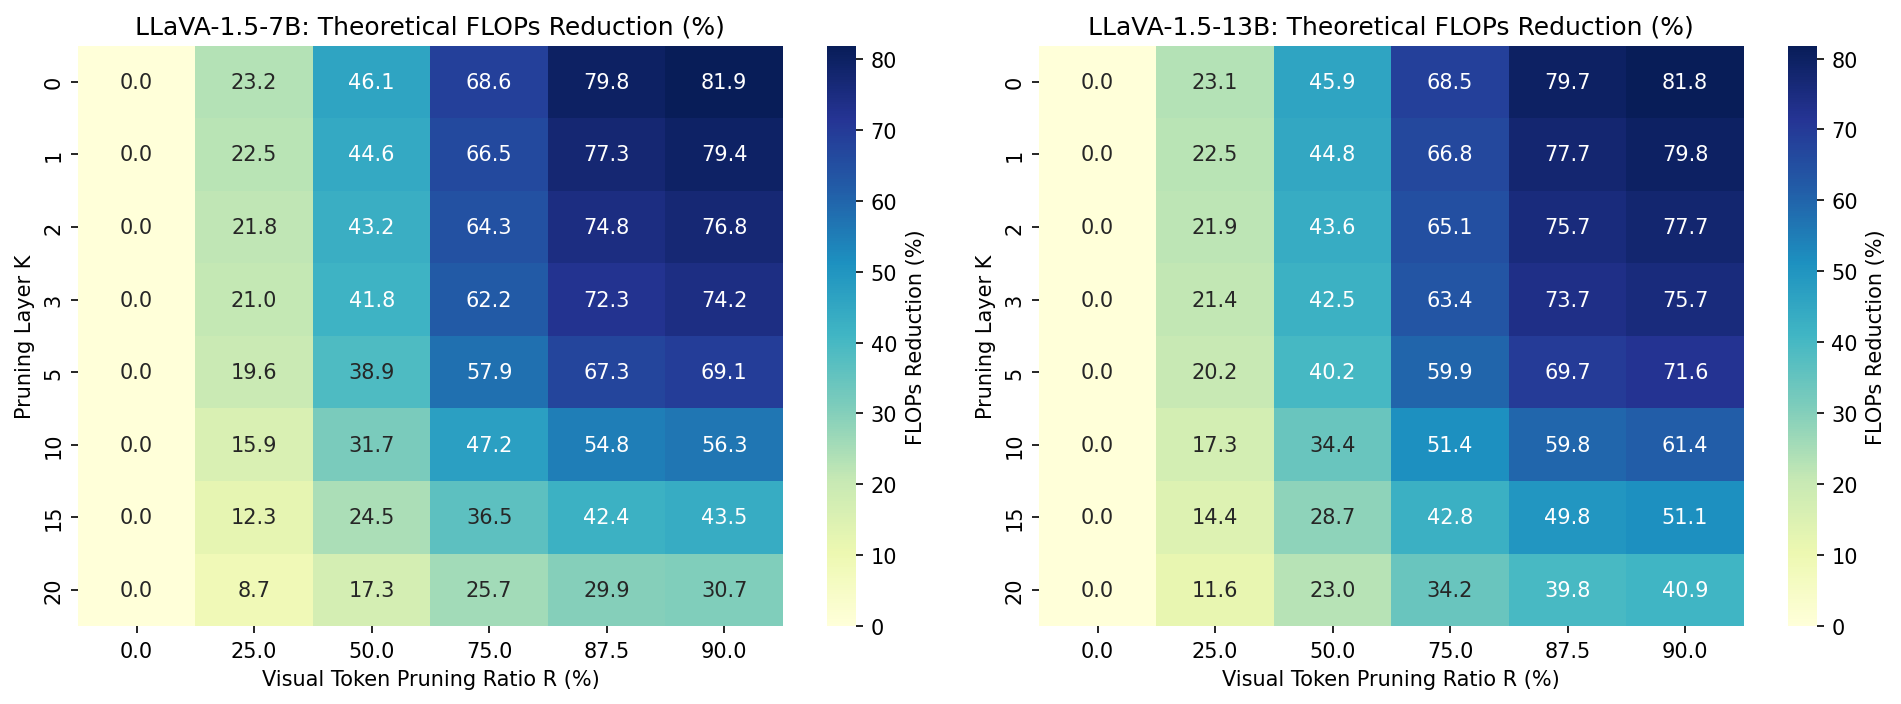

In [12]:
flops_dir = os.path.join(OUTPUT_ROOT, "exp0_flops")
os.makedirs(flops_dir, exist_ok=True)

model_specs = {
    "LLaVA-1.5-7B": dict(num_layers=32, hidden_size=4096, intermediate_size=11008),
    "LLaVA-1.5-13B": dict(num_layers=40, hidden_size=5120, intermediate_size=13824),
}
ks_grid = [0, 1, 2, 3, 5, 10, 15, 20]
rs_grid = [0.0, 0.25, 0.50, 0.75, 0.875, 0.90]

rows = []
for mname, spec in model_specs.items():
    for k in ks_grid:
        for r in rs_grid:
            res = compute_fastv_flops_ratio(
                num_layers=spec["num_layers"],
                fastv_k=k,
                fastv_r=r,
                n_image_tokens=576,
                n_text_tokens=60,
                hidden_size=spec["hidden_size"],
                intermediate_size=spec["intermediate_size"],
            )
            rows.append(
                {
                    "Model": mname,
                    "K": k,
                    "R (%)": round(r * 100, 1),
                    "FLOPs Ratio (%)": round(res["flops_ratio_pct"], 2),
                    "FLOPs Reduction (%)": round(res["flops_reduction_pct"], 2),
                    "Baseline TFLOPs": round(res["baseline_tflops"], 3),
                    "FastV TFLOPs": round(res["fastv_tflops"], 3),
                }
            )

flops_df = pd.DataFrame(rows)
display(flops_df[(flops_df["K"].isin([2, 3])) & (flops_df["R (%)"].isin([0.0, 25.0, 50.0, 75.0, 87.5]))])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), dpi=150)
for ax, mname in zip(axes, model_specs.keys()):
    sub = flops_df[flops_df["Model"] == mname].pivot(index="K", columns="R (%)", values="FLOPs Reduction (%)")
    sns.heatmap(sub, annot=True, fmt=".1f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "FLOPs Reduction (%)"})
    ax.set_title(f"{mname}: Theoretical FLOPs Reduction (%)")
    ax.set_xlabel("Visual Token Pruning Ratio R (%)")
    ax.set_ylabel("Pruning Layer K")

plt.tight_layout()
flops_plot_path = os.path.join(flops_dir, "theoretical_flops_heatmap.png")
plt.savefig(flops_plot_path, bbox_inches="tight")
plt.show()
flops_df.to_csv(os.path.join(flops_dir, "theoretical_flops.csv"), index=False)

---
## Section 2 — Load LLaVA-1.5 Once & Run Vanilla vs FastV Acceleration Demo (KV-Cache & Non-Cache)

We load `MODEL_ID` **once** using `load_llava_model(...)` with `attn_implementation="eager"` and attach our `FastVController`.
We then benchmark **Vanilla Decoding**, **FastV ($K=2, R=50\%$)**, and **FastV ($K=3, R=75\%$)** on the COCO cats image (`000000039769.jpg`), testing both `use_cache=True` (KV-cache pruning) and `use_cache=False` (original paper dynamic re-pruning).

In [13]:
print(f"Loading {MODEL_ID} (quantization={QUANTIZATION}) once for all experiments...")
model, processor, controller = load_llava_model(
    model_id=MODEL_ID,
    quantization=QUANTIZATION,
    dtype=DTYPE,
    attn_implementation="eager",
    fastv_config=FastVConfig(use_fastv=False),
    device_map={"": "cuda:0"} if torch.cuda.is_available() else None,
)
DEVICE = next(model.parameters()).device
IMAGE_TOKEN_INDEX = int(getattr(model.config, "image_token_index", 32000))
TEXT_CFG = getattr(model.config, "text_config", model.config)
NUM_LAYERS = int(getattr(TEXT_CFG, "num_hidden_layers", 32))
HIDDEN_SIZE = int(getattr(TEXT_CFG, "hidden_size", 4096))
INTERMEDIATE_SIZE = int(getattr(TEXT_CFG, "intermediate_size", 11008))
print(f"Loaded on {DEVICE} | layers={NUM_LAYERS}, hidden={HIDDEN_SIZE}, intermediate={INTERMEDIATE_SIZE}")

Loading llava-hf/llava-1.5-7b-hf (quantization=4bit) once for all experiments...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/70.1k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

... (9 outputs left out)

tokenizer.model: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/41.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/552 [00:00<?, ?B/s]

Loaded on cuda:0 | layers=32, hidden=4096, intermediate=11008


In [14]:
demo_dir = os.path.join(OUTPUT_ROOT, "exp0_demo")
os.makedirs(demo_dir, exist_ok=True)

demo_img_url = "http://images.cocodataset.org/val2017/000000039769.jpg"
try:
    demo_image = Image.open(BytesIO(requests.get(demo_img_url, timeout=20).content)).convert("RGB")
except Exception:
    demo_image = Image.open(os.path.join(REPO_ROOT, "figs", "example.jpg")).convert("RGB")

demo_prompt = "What are these? Describe the image in details"
demo_inputs, demo_span = prepare_llava_inputs(
    processor=processor,
    prompt=demo_prompt,
    image=demo_image,
    device=DEVICE,
    dtype=DTYPE,
    include_system_prompt=False,
    image_token_index=IMAGE_TOKEN_INDEX,
)
print(f"Prompt length={demo_inputs['input_ids'].shape[1]} | Detected image span={demo_span}")

demo_configs = [
    ("Vanilla (KV-cache=True)", FastVConfig(use_fastv=False), True),
    ("FastV K=2, R=50% (KV-cache=True)", FastVConfig(use_fastv=True, fastv_k=2, fastv_r=0.50, mode="inplace"), True),
    ("FastV K=3, R=75% (KV-cache=True)", FastVConfig(use_fastv=True, fastv_k=3, fastv_r=0.75, mode="inplace"), True),
    ("Vanilla (KV-cache=False)", FastVConfig(use_fastv=False), False),
    ("FastV K=2, R=50% (KV-cache=False)", FastVConfig(use_fastv=True, fastv_k=2, fastv_r=0.50, mode="inplace"), False),
    ("FastV K=3, R=75% (KV-cache=False)", FastVConfig(use_fastv=True, fastv_k=3, fastv_r=0.75, mode="inplace"), False),
]

demo_rows = []
demo_outputs = {}
prompt_len = int(demo_inputs["input_ids"].shape[1])
img_len = demo_span[1] if demo_span else 576
txt_len = max(1, prompt_len - img_len)

for label, cfg, use_cache in demo_configs:
    controller.update_config(cfg)
    max_toks = 128 if use_cache else 64
    if torch.cuda.is_available():
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter()
    with torch.inference_mode():
        gen = model.generate(
            **demo_inputs,
            min_new_tokens=max_toks,
            max_new_tokens=max_toks,
            do_sample=False,
            use_cache=use_cache,
            return_dict_in_generate=True,
        )
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - t0
    peak_mem = torch.cuda.max_memory_allocated() / (1024 ** 3) if torch.cuda.is_available() else 0.0
    n_gen = int(gen.sequences.shape[1] - prompt_len)
    decoded = processor.tokenizer.decode(gen.sequences[0, prompt_len:], skip_special_tokens=True).strip()
    flops = compute_fastv_flops_ratio(
        NUM_LAYERS, cfg.fastv_k, cfg.fastv_r if cfg.use_fastv else 0.0, img_len, txt_len, HIDDEN_SIZE, INTERMEDIATE_SIZE
    )
    demo_outputs[label] = decoded
    demo_rows.append(
        {
            "Config": label,
            "Tokens": n_gen,
            "Total Time (s)": round(elapsed, 3),
            "ms / token": round((elapsed / max(1, n_gen)) * 1000.0, 2),
            "Peak GPU (GiB)": round(peak_mem, 2),
            "FLOPs (%)": round(flops["flops_ratio_pct"], 1),
        }
    )

demo_df = pd.DataFrame(demo_rows)
display(demo_df)
for label in ("Vanilla (KV-cache=True)", "FastV K=2, R=50% (KV-cache=True)", "FastV K=3, R=75% (KV-cache=True)"):
    print(f"\n--- {label} ---\n{demo_outputs[label][:400]}")

demo_df.to_csv(os.path.join(demo_dir, "demo_benchmark.csv"), index=False)

Prompt length=598 | Detected image span=(5, 576)


,Config,Tokens,Total Time (s),ms / token,Peak GPU (GiB),FLOPs (%)
0,Vanilla (KV-cache=True),128,10.004,78.15,4.29,100.0
1,"FastV K=2, R=50% (KV-cache=True)",128,8.041,62.82,4.48,54.1
2,"FastV K=3, R=75% (KV-cache=True)",128,7.937,62.01,4.27,34.0
3,Vanilla (KV-cache=False),64,19.553,305.52,4.17,100.0
4,"FastV K=2, R=50% (KV-cache=False)",64,14.126,220.73,4.00,54.1
5,"FastV K=3, R=75% (KV-cache=False)",64,11.310,176.72,4.00,34.0



--- Vanilla (KV-cache=True) ---
The image features two cats lying on a pink couch. One cat is positioned on the left side of the couch, while the other cat is on the right side. The couch is covered with a blanket, providing a comfortable resting spot for the cats.

In the scene, there are also two remote controls, one located near the left cat and the other near the right cat. Additionally, there is a TV situated in the backgro

--- FastV K=2, R=50% (KV-cache=True) ---
The image features two cats lying on a pink couch. One cat is positioned on the left side of the couch, while the other cat is on the right side. Both cats are sleeping peacefully, enjoying the comfortable space provided by the couch. The scene is a cozy and relaxing depiction of the cats' resting time. The couch occupies most of the image, with the cats taking up a significant portion of the spac

--- FastV K=3, R=75% (KV-cache=True) ---
The image features a pink couch with a remote control placed on it. The remote co

---
## Section 3 — Experiment 1: Inefficient Visual Attention Visualization (Paper Figures 2 & 3)

Reproduces the core empirical observation of the paper:
* **Figure 2**: Pooled log-scale attention heatmaps across layers of LLaVA-1.5 showing that visual tokens (marked in red) receive dense attention only in Layers 1–2, after which attention concentrates overwhelmingly on system/anchor and text tokens.
* **Figure 3**: Quantitative per-layer attention share and **Visual Attention Efficiency** (`visual_attention_share / visual_token_fraction`) collapsing sharply after Layer 2.

Generated description (img span=35:611):
The image features a unique and eye-catching toy, resembling a red and orange fire-breathing dragon or a flaming phoenix. The toy is wearing glasses, giving it a quirky and fun appearance. The fire-breathing dragon is standing on a surface, possibly a table, and appears to be the main focus of the scene.

Visual Attention Share — Layer 1: 0.623 | Layer 2: 0.250 | Layer 3: 0.098 | Deep Avg (Layers 3..32): 0.085


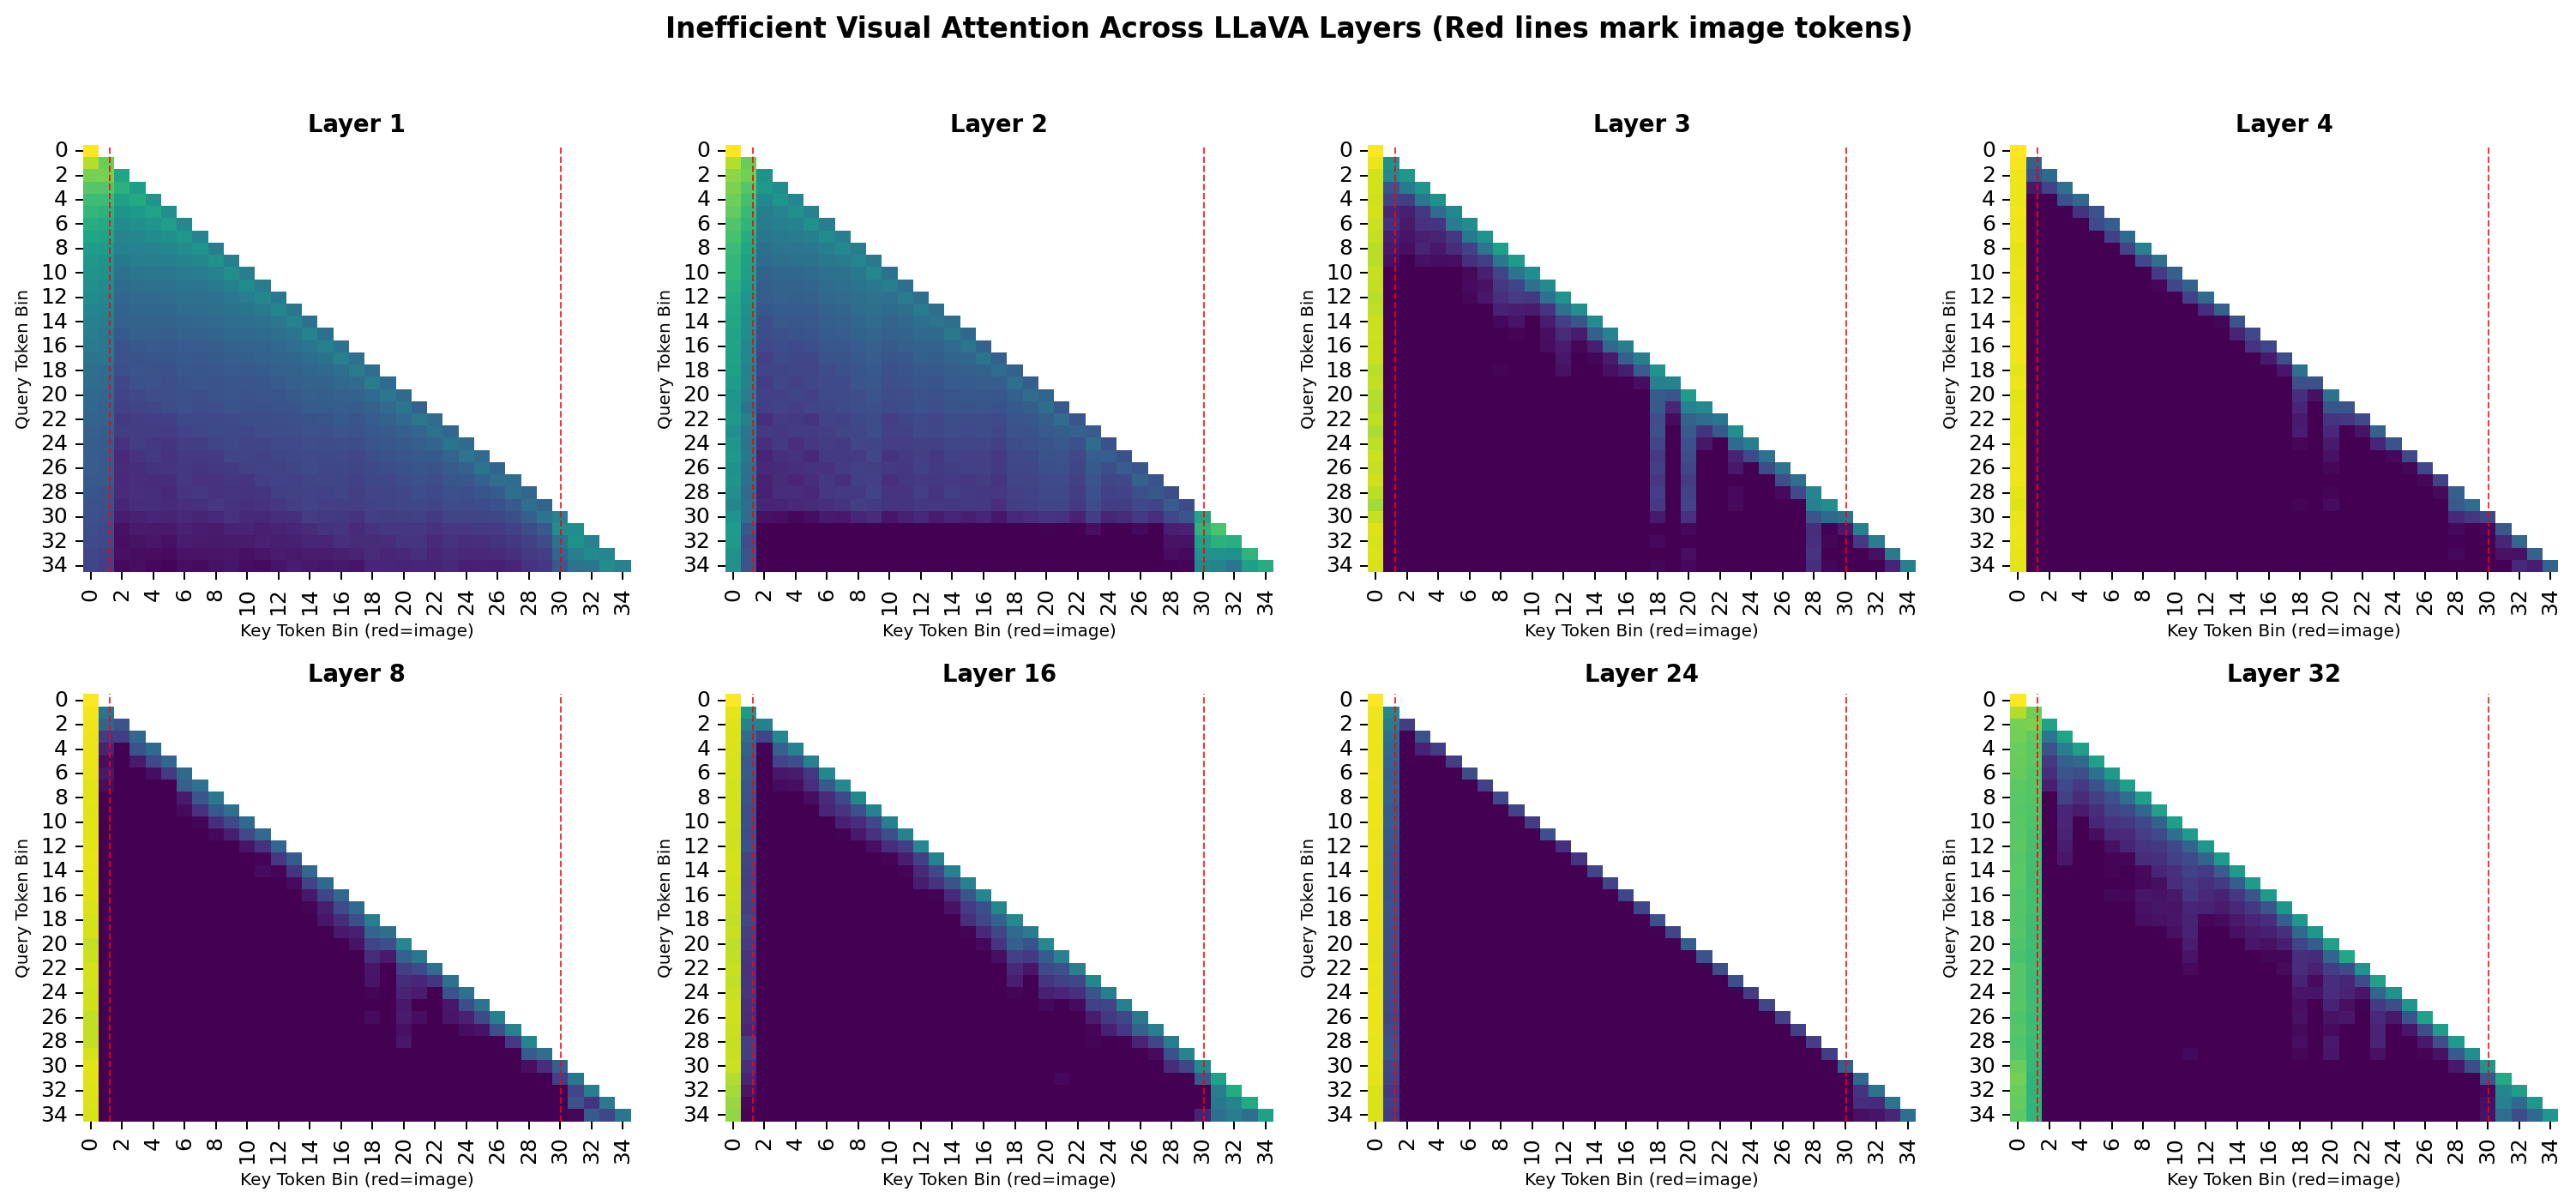

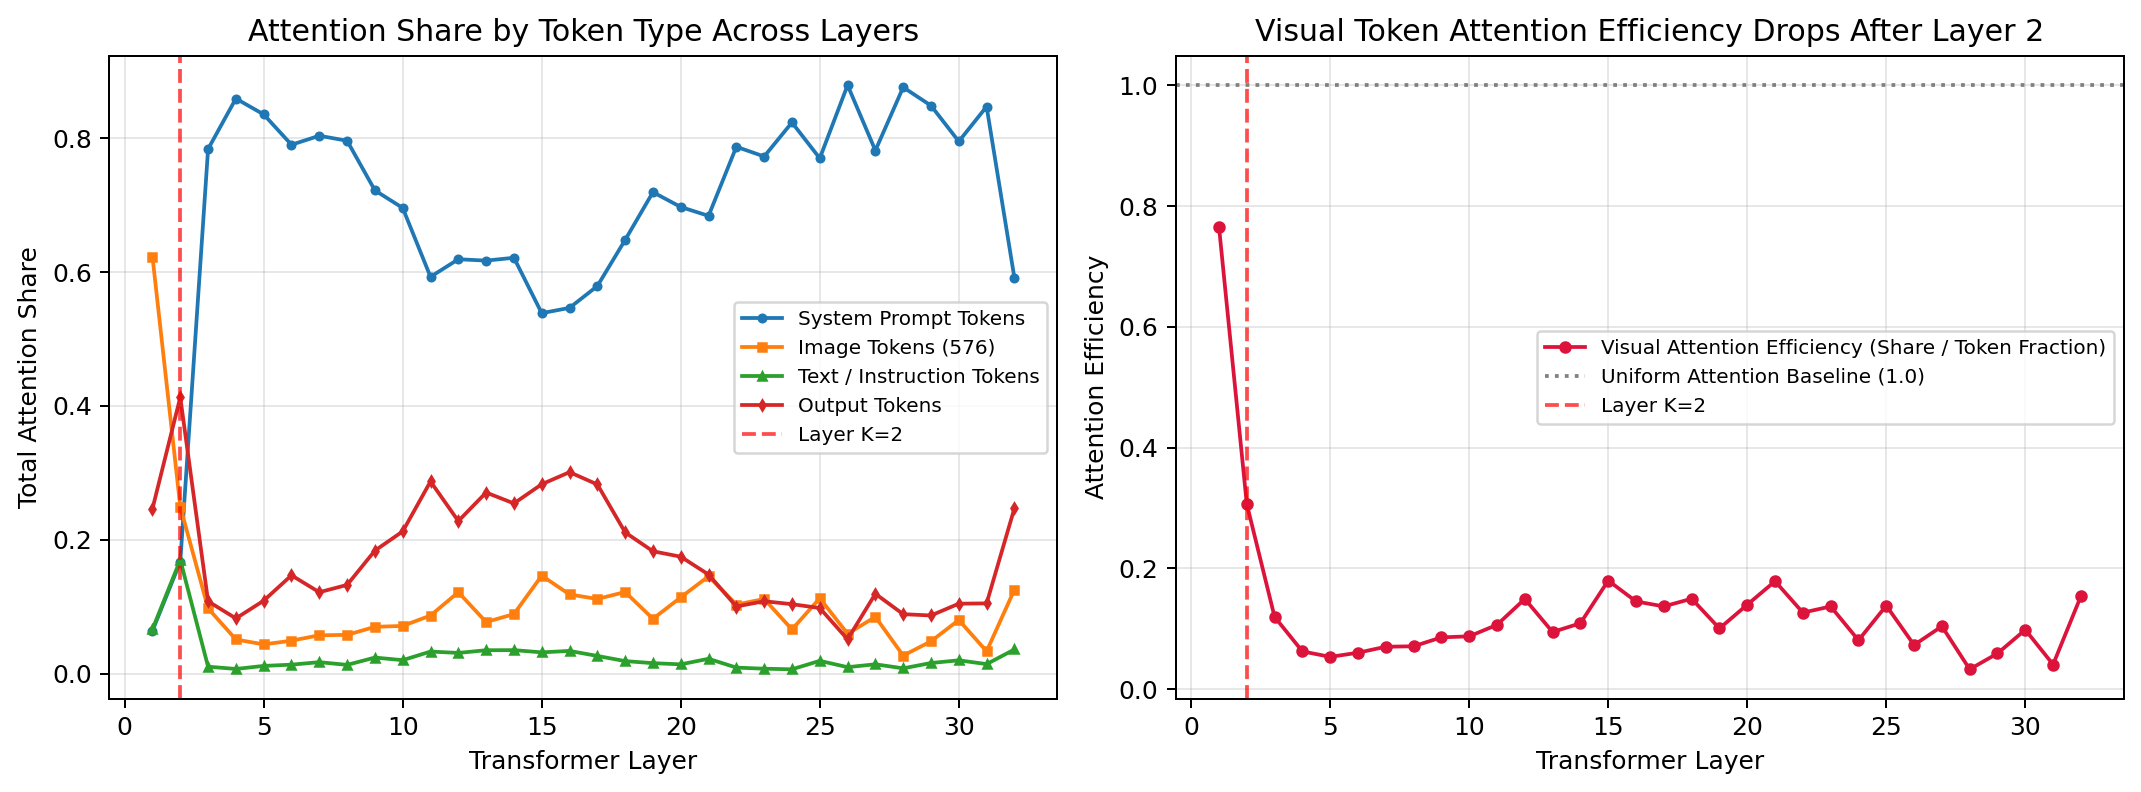

In [15]:
from FastV.inference.plot_inefficient_attention import (
    plot_attention_efficiency,
    plot_attention_grid,
    visualize_attention,
)

exp1_dir = os.path.join(OUTPUT_ROOT, "exp1_attention")
exp1_maps_dir = os.path.join(exp1_dir, "attn_maps")
os.makedirs(exp1_maps_dir, exist_ok=True)

controller.disable()
vis_image_path = os.path.join(REPO_ROOT, "src", "LLaVA", "images", "llava_logo.png")
vis_prompt = "Describe the image in details."
vis_image = Image.open(vis_image_path).convert("RGB")

# 1. Generate response cleanly with Vanilla LLaVA
vis_inputs, vis_span = prepare_llava_inputs(
    processor=processor,
    prompt=vis_prompt,
    image=vis_image,
    device=DEVICE,
    dtype=DTYPE,
    include_system_prompt=True,
    image_token_index=IMAGE_TOKEN_INDEX,
)
vis_prompt_len = int(vis_inputs["input_ids"].shape[1])
vis_img_start, vis_img_len = vis_span if vis_span else (35, 576)

with torch.inference_mode():
    vis_gen = model.generate(
        **vis_inputs,
        do_sample=False,
        max_new_tokens=96,
        use_cache=True,
        return_dict_in_generate=True,
    )
vis_output_text = processor.tokenizer.decode(
    vis_gen.sequences[0, vis_prompt_len:], skip_special_tokens=True
).strip()
print(f"Generated description (img span={vis_img_start}:{vis_img_start + vis_img_len}):\n{vis_output_text}\n")

# 2. Extract full layer-wise attention tensors on prompt + generated output
full_vis_inputs, _ = prepare_llava_inputs(
    processor=processor,
    prompt=vis_prompt,
    image=vis_image,
    device=DEVICE,
    dtype=DTYPE,
    include_system_prompt=True,
    append_output=" " + vis_output_text,
    image_token_index=IMAGE_TOKEN_INDEX,
)
with torch.inference_mode():
    fwd_out = model(**full_vis_inputs, output_attentions=True, use_cache=False, return_dict=True)

attentions_cpu = [a.detach().cpu() for a in fwd_out.attentions]
del fwd_out
if torch.cuda.is_available():
    torch.cuda.empty_cache()

efficiency = compute_layer_attention_efficiency(
    attentions=attentions_cpu,
    image_start=vis_img_start,
    image_length=vis_img_len,
    instruction_end=vis_prompt_len,
)

grid_path = os.path.join(exp1_dir, "attn_grid.png")
eff_path = os.path.join(exp1_dir, "attention_efficiency.png")
plot_attention_grid(attentions_cpu, grid_path, image_start=vis_img_start, image_length=vis_img_len)
plot_attention_efficiency(efficiency, eff_path)

# Also save key individual heatmaps (Layers 1, 2, 3, 5, 10, 20, 32)
for l_idx in [0, 1, 2, 4, 9, 19, len(attentions_cpu) - 1]:
    if l_idx < len(attentions_cpu):
        visualize_attention(
            attentions_cpu[l_idx],
            output_path=os.path.join(exp1_maps_dir, f"atten_map_{l_idx}.png"),
            title=f"Layer {l_idx + 1}",
            image_start=vis_img_start,
            image_length=vis_img_len,
        )

with open(os.path.join(exp1_dir, "attention_efficiency.json"), "w") as f:
    json.dump(efficiency, f, indent=2)

eff_df = pd.DataFrame(efficiency)
print(
    f"Visual Attention Share — Layer 1: {eff_df.loc[0, 'image_total']:.3f} | "
    f"Layer 2: {eff_df.loc[1, 'image_total']:.3f} | "
    f"Layer 3: {eff_df.loc[2, 'image_total']:.3f} | "
    f"Deep Avg (Layers 3..{len(eff_df)}): {eff_df.loc[2:, 'image_total'].mean():.3f}"
)
display(IPyImage(filename=grid_path))
display(IPyImage(filename=eff_path))
del attentions_cpu

---
## Section 4 — Experiment 2: A-OKVQA Accuracy, Latency & GPU Memory Benchmark (Paper Table 4)

Reproduces the A-OKVQA inplace token-dropping latency & accuracy benchmark (`eval_aokvqa_latency_fastv_inplace.sh`) on the repository's bundled `./data/aokvqa/validation` dataset across:
* **Vanilla Baseline** ($R = 0\%$)
* **FastV Inplace ($K=2, R=25\%$)** (keep 432 / 576 visual tokens)
* **FastV Inplace ($K=2, R=50\%$)** (keep 288 / 576 visual tokens)
* **FastV Inplace ($K=2, R=75\%$)** (keep 144 / 576 visual tokens)
* **FastV Inplace ($K=2, R=87.5\%$)** (keep 72 / 576 visual tokens)

We measure **Accuracy (%)**, **Time-to-First-Token Latency (s/sample)**, **Speedup**, **Peak GPU Memory (GiB)**, and **Theoretical FLOPs Ratio (%)**.

Loaded 100 A-OKVQA validation samples.


Vanilla Baseline:   0%|          | 0/100 [00:00<?, ?it/s]

FastV K=2, R=25% (rank=432):   0%|          | 0/100 [00:00<?, ?it/s]

FastV K=2, R=50% (rank=288):   0%|          | 0/100 [00:00<?, ?it/s]

FastV K=2, R=75% (rank=144):   0%|          | 0/100 [00:00<?, ?it/s]

FastV K=2, R=87.5% (rank=72):   0%|          | 0/100 [00:00<?, ?it/s]

,Setting,K,R (%),Accuracy (%),Latency / 1st Token (s),Peak GPU (GiB),FLOPs (%),Speedup (x)
0,Vanilla Baseline,-,0.0,76.0,0.4051,4.36,100.0,1.00
1,"FastV K=2, R=25% (rank=432)",2,25.0,77.0,0.3239,4.36,79.6,1.25
2,"FastV K=2, R=50% (rank=288)",2,50.0,75.0,0.2737,4.36,59.4,1.48
3,"FastV K=2, R=75% (rank=144)",2,75.0,73.0,0.2201,4.36,39.5,1.84
4,"FastV K=2, R=87.5% (rank=72)",2,87.5,67.0,0.2047,4.36,29.7,1.98


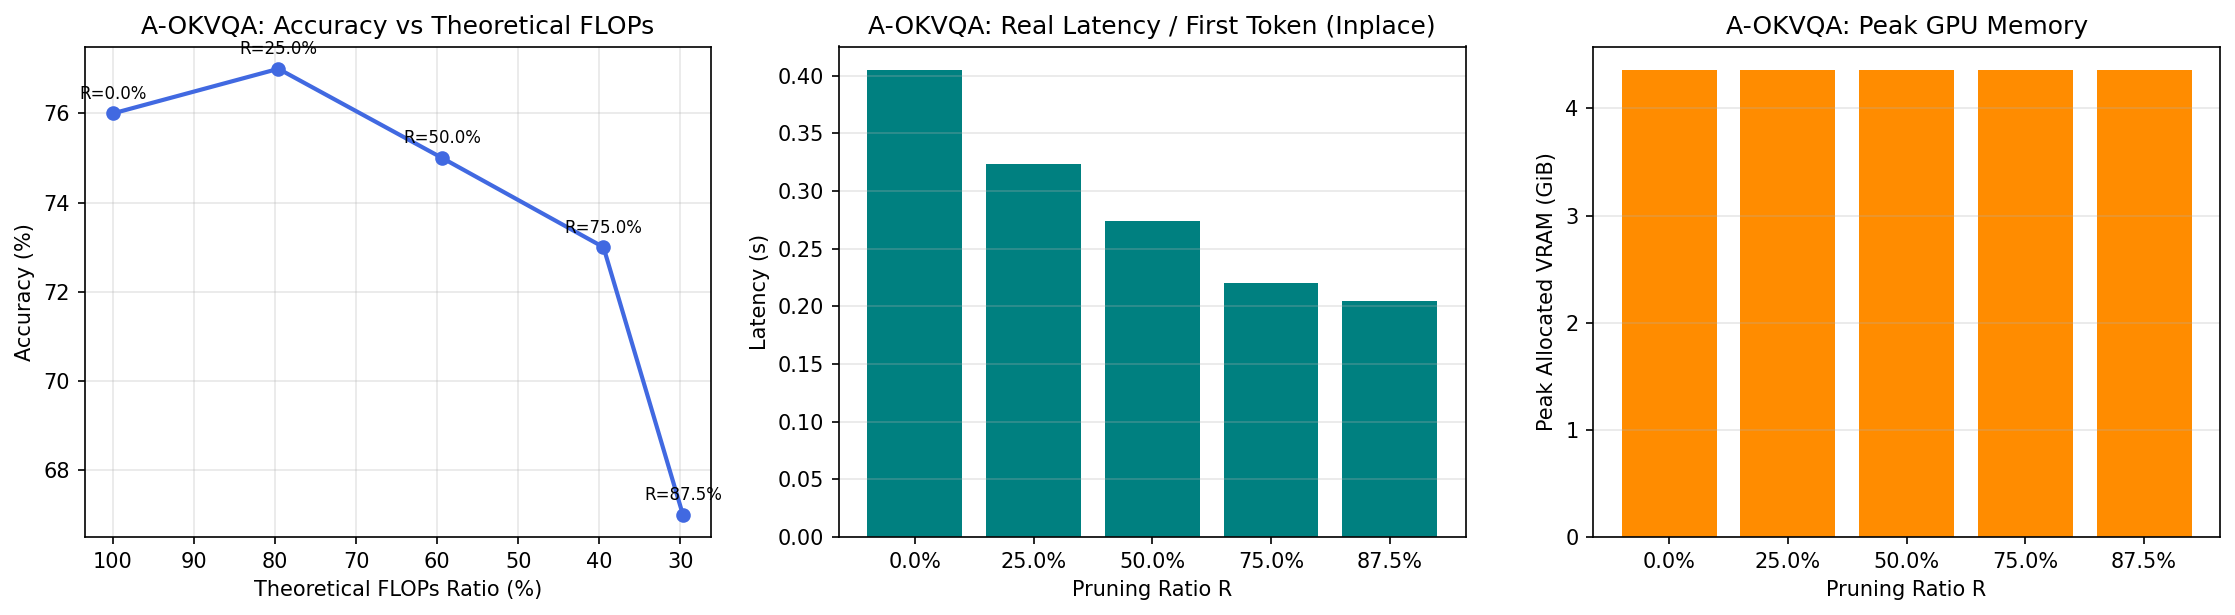

In [16]:
from FastV.inference.eval.inference_aokvqa import (
    TEMPLATE as AOKVQA_TEMPLATE,
    compute_acc as aokvqa_compute_acc,
    format_answer as aokvqa_format_answer,
    format_choices as aokvqa_format_choices,
    load_aokvqa_dataset,
)

exp2_dir = os.path.join(OUTPUT_ROOT, "exp2_aokvqa")
os.makedirs(exp2_dir, exist_ok=True)

aokvqa_ds = load_aokvqa_dataset(os.path.join(REPO_ROOT, "data", "aokvqa", "validation"))
if AOKVQA_MAX_SAMPLES is not None and AOKVQA_MAX_SAMPLES < len(aokvqa_ds):
    aokvqa_ds = aokvqa_ds.select(range(AOKVQA_MAX_SAMPLES))

aok_images = aokvqa_ds["image"]
aok_prompts = [
    AOKVQA_TEMPLATE.format(question=q, options=aokvqa_format_choices(c))
    for q, c in zip(aokvqa_ds["question"], aokvqa_ds["choices"])
]
aok_labels = [aokvqa_format_answer(idx) for idx in aokvqa_ds["correct_choice_idx"]]
print(f"Loaded {len(aok_prompts)} A-OKVQA validation samples.")

aok_configs = [
    ("Vanilla Baseline", FastVConfig(use_fastv=False)),
    ("FastV K=2, R=25% (rank=432)", FastVConfig(use_fastv=True, fastv_k=2, attention_rank=432, mode="inplace")),
    ("FastV K=2, R=50% (rank=288)", FastVConfig(use_fastv=True, fastv_k=2, attention_rank=288, mode="inplace")),
    ("FastV K=2, R=75% (rank=144)", FastVConfig(use_fastv=True, fastv_k=2, attention_rank=144, mode="inplace")),
    ("FastV K=2, R=87.5% (rank=72)", FastVConfig(use_fastv=True, fastv_k=2, attention_rank=72, mode="inplace")),
]

aok_results = []
warmup = min(3, max(0, len(aok_prompts) - 1))

for name, cfg in aok_configs:
    controller.update_config(cfg)
    preds, lats, plens = [], [], []
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    for idx, (prompt, img) in enumerate(tqdm(zip(aok_prompts, aok_images), total=len(aok_prompts), desc=name)):
        inp, span = prepare_llava_inputs(
            processor=processor,
            prompt=prompt,
            image=img,
            device=DEVICE,
            dtype=DTYPE,
            include_system_prompt=True,
            image_token_index=IMAGE_TOKEN_INDEX,
        )
        plen = int(inp["input_ids"].shape[1])
        plens.append(plen)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        with torch.inference_mode():
            gen = model.generate(
                **inp,
                do_sample=False,
                max_new_tokens=1,
                use_cache=False,
                return_dict_in_generate=True,
            )
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        dt = time.perf_counter() - t0
        if idx >= warmup:
            lats.append(dt)
        dec = processor.tokenizer.decode(gen.sequences[0, plen:], skip_special_tokens=True).strip()
        preds.append(dec)

    acc = aokvqa_compute_acc(preds, aok_labels) * 100.0
    avg_lat = float(np.mean(lats)) if lats else 0.0
    peak_mem = torch.cuda.max_memory_allocated() / (1024 ** 3) if torch.cuda.is_available() else 0.0
    r_eff = cfg.effective_pruning_ratio(576) if cfg.use_fastv else 0.0
    avg_txt = max(1, int(round(np.mean(plens) - 576)))
    flops = compute_fastv_flops_ratio(
        NUM_LAYERS, cfg.fastv_k, r_eff, 576, avg_txt, HIDDEN_SIZE, INTERMEDIATE_SIZE
    )
    aok_results.append(
        {
            "Setting": name,
            "K": cfg.fastv_k if cfg.use_fastv else "-",
            "R (%)": round(r_eff * 100.0, 1),
            "Accuracy (%)": round(acc, 2),
            "Latency / 1st Token (s)": round(avg_lat, 4),
            "Peak GPU (GiB)": round(peak_mem, 2),
            "FLOPs (%)": round(flops["flops_ratio_pct"], 1),
        }
    )

aok_df = pd.DataFrame(aok_results)
base_lat = aok_df.loc[0, "Latency / 1st Token (s)"]
aok_df["Speedup (x)"] = (base_lat / aok_df["Latency / 1st Token (s)"]).round(2)
display(aok_df)

# Save & plot A-OKVQA results
aok_df.to_csv(os.path.join(exp2_dir, "aokvqa_results.csv"), index=False)
with open(os.path.join(exp2_dir, "aokvqa_results.json"), "w") as f:
    json.dump(aok_df.to_dict(orient="records"), f, indent=2)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), dpi=150)
axes[0].plot(aok_df["FLOPs (%)"], aok_df["Accuracy (%)"], marker="o", linewidth=2, color="royalblue")
for _, row in aok_df.iterrows():
    axes[0].annotate(f"R={row['R (%)']}%", (row["FLOPs (%)"], row["Accuracy (%)"]), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
axes[0].set_title("A-OKVQA: Accuracy vs Theoretical FLOPs")
axes[0].set_xlabel("Theoretical FLOPs Ratio (%)")
axes[0].set_ylabel("Accuracy (%)")
axes[0].invert_xaxis()
axes[0].grid(True, alpha=0.3)

axes[1].bar(aok_df["R (%)"].astype(str) + "%", aok_df["Latency / 1st Token (s)"], color="teal")
axes[1].set_title("A-OKVQA: Real Latency / First Token (Inplace)")
axes[1].set_xlabel("Pruning Ratio R")
axes[1].set_ylabel("Latency (s)")
axes[1].grid(True, axis="y", alpha=0.3)

axes[2].bar(aok_df["R (%)"].astype(str) + "%", aok_df["Peak GPU (GiB)"], color="darkorange")
axes[2].set_title("A-OKVQA: Peak GPU Memory")
axes[2].set_xlabel("Pruning Ratio R")
axes[2].set_ylabel("Peak Allocated VRAM (GiB)")
axes[2].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(exp2_dir, "aokvqa_benchmark.png"), bbox_inches="tight")
plt.show()

---
## Section 5 — Experiment 3: OCR-VQA Hyperparameter Ablation over $K$ and $R$ (Paper Figure 7)

Reproduces the paper's **Figure 7** (`eval_ocrvqa_fastv_token_mask.sh`) ablation study on `howard-hou/OCR-VQA`:
* Evaluates **token-masking mode** (`mode="mask"`) across pruning layers $K$ (including **$K=0$**, the random visual token pruning baseline!) and pruning ratios $R \in \{0\%, 25\%, 50\%, 75\%, 87.5\%\}$.
* Computes exact ROUGE-L ($\beta=1.2$, matching `pycocoevalcap`) and plots both:
  1. **OCR-VQA ROUGE-L vs Pruning Layer $K$** (reproducing `figs/ablation_ocrvqa.png` / Paper Figure 7)
  2. **OCR-VQA Performance vs FLOPs Trade-off Curve** (reproducing Paper Figure 1)

Streaming OCR-VQA test samples (max_examples=40, max_questions=60)...


README.md:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

Loaded 60 OCR-VQA QA pairs.


OCR-VQA Baseline:   0%|          | 0/60 [00:00<?, ?it/s]

OCR-VQA Baseline (R=0%): ROUGE-L = 64.17%


OCR-VQA K=0, R=25%:   0%|          | 0/60 [00:00<?, ?it/s]

... (16 outputs left out)

OCR-VQA K=5, R=50%:   0%|          | 0/60 [00:00<?, ?it/s]

OCR-VQA K=5, R=75%:   0%|          | 0/60 [00:00<?, ?it/s]

OCR-VQA K=5, R=87%:   0%|          | 0/60 [00:00<?, ?it/s]

R (%),0.0,25.0,50.0,75.0,87.5
K,,,,,
0,64.17,62.44,60.36,57.76,49.01
1,64.17,63.83,61.19,49.48,39.56
2,64.17,64.22,64.23,61.09,49.64
3,64.17,64.17,64.22,63.06,53.04
5,64.17,64.17,63.27,59.16,43.16


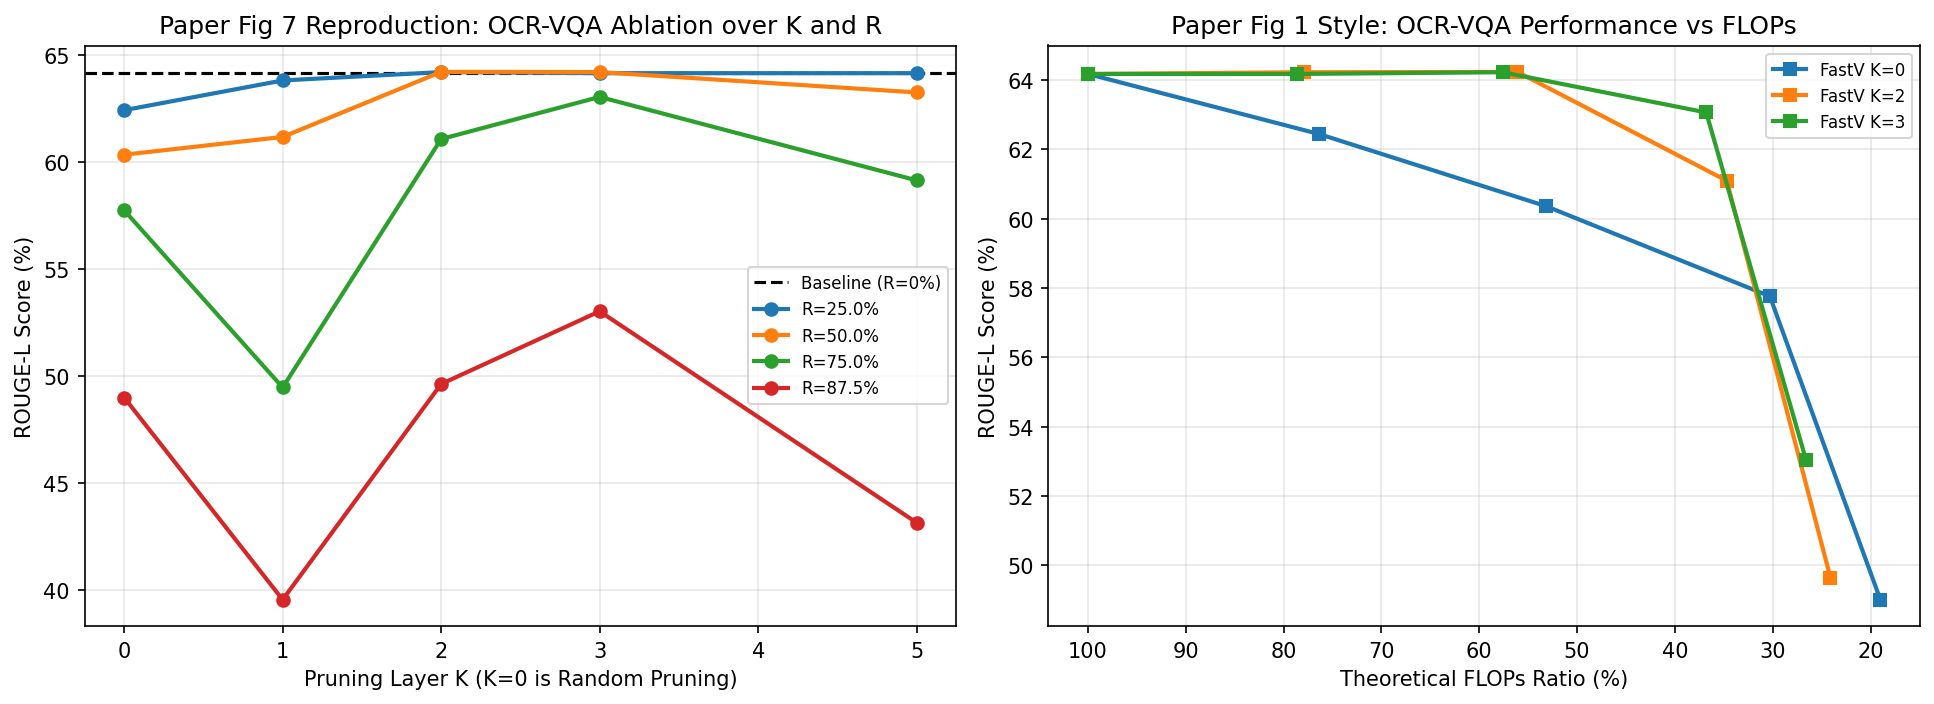

In [17]:
from FastV.inference.eval.inference_ocrvqa import clean_text as ocr_clean_text, load_ocrvqa_samples

exp3_dir = os.path.join(OUTPUT_ROOT, "exp3_ocrvqa")
os.makedirs(exp3_dir, exist_ok=True)

print(f"Streaming OCR-VQA test samples (max_examples={OCRVQA_MAX_EXAMPLES}, max_questions={OCRVQA_MAX_QUESTIONS})...")
ocr_images, ocr_prompts, ocr_labels = load_ocrvqa_samples(
    max_examples=OCRVQA_MAX_EXAMPLES,
    max_questions=OCRVQA_MAX_QUESTIONS,
)
cleaned_ocr_refs = [[ocr_clean_text(t) for t in ref_list] for ref_list in ocr_labels]
print(f"Loaded {len(ocr_prompts)} OCR-VQA QA pairs.")


def eval_ocrvqa_config(cfg: FastVConfig, desc: str):
    controller.update_config(cfg)
    preds = []
    plens = []
    t0 = time.perf_counter()
    for prompt, img in tqdm(zip(ocr_prompts, ocr_images), total=len(ocr_prompts), desc=desc, leave=False):
        inp, _ = prepare_llava_inputs(
            processor=processor,
            prompt=prompt,
            image=img,
            device=DEVICE,
            dtype=DTYPE,
            include_system_prompt=True,
            image_token_index=IMAGE_TOKEN_INDEX,
        )
        plen = int(inp["input_ids"].shape[1])
        plens.append(plen)
        with torch.inference_mode():
            gen = model.generate(
                **inp,
                do_sample=False,
                max_new_tokens=32,
                use_cache=True,
                return_dict_in_generate=True,
            )
        dec = processor.tokenizer.decode(gen.sequences[0, plen:], skip_special_tokens=True).strip()
        preds.append(dec)
    elapsed = time.perf_counter() - t0
    cleaned_preds = [ocr_clean_text(p) for p in preds]
    avg_rouge, _ = compute_rouge_l(cleaned_ocr_refs, cleaned_preds)
    avg_txt = max(1, int(round(np.mean(plens) - 576)))
    return avg_rouge * 100.0, elapsed / max(1, len(preds)), avg_txt


# Evaluate baseline (R=0%) once
base_rouge, base_lat, avg_ocr_txt = eval_ocrvqa_config(FastVConfig(use_fastv=False), "OCR-VQA Baseline")
print(f"OCR-VQA Baseline (R=0%): ROUGE-L = {base_rouge:.2f}%")

ocr_rows = []
for k in OCRVQA_KS:
    for r in OCRVQA_RS:
        if r == 0.0:
            score = base_rouge
            lat = base_lat
        else:
            cfg = FastVConfig(use_fastv=True, fastv_k=k, fastv_r=r, mode="mask", random_seed=42)
            score, lat, _ = eval_ocrvqa_config(cfg, f"OCR-VQA K={k}, R={int(r*100)}%")
        flops = compute_fastv_flops_ratio(
            NUM_LAYERS, k, r, 576, avg_ocr_txt, HIDDEN_SIZE, INTERMEDIATE_SIZE
        )
        ocr_rows.append(
            {
                "K": k,
                "R (%)": round(r * 100.0, 1),
                "Kept Tokens": int(round(576 * (1.0 - r))),
                "ROUGE-L (%)": round(score, 2),
                "FLOPs (%)": round(flops["flops_ratio_pct"], 1),
                "Avg Latency (s)": round(lat, 4),
            }
        )

ocr_df = pd.DataFrame(ocr_rows)
ocr_pivot = ocr_df.pivot(index="K", columns="R (%)", values="ROUGE-L (%)")
display(ocr_pivot)

ocr_df.to_csv(os.path.join(exp3_dir, "ocrvqa_ablation.csv"), index=False)
with open(os.path.join(exp3_dir, "ocrvqa_ablation.json"), "w") as f:
    json.dump(ocr_df.to_dict(orient="records"), f, indent=2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), dpi=150)
for r_pct in sorted(ocr_df["R (%)"].unique()):
    if r_pct == 0.0:
        ax1.axhline(base_rouge, color="black", linestyle="--", label="Baseline (R=0%)")
        continue
    sub = ocr_df[ocr_df["R (%)"] == r_pct].sort_values("K")
    ax1.plot(sub["K"], sub["ROUGE-L (%)"], marker="o", linewidth=2, label=f"R={r_pct}%")
ax1.set_title("Paper Fig 7 Reproduction: OCR-VQA Ablation over K and R")
ax1.set_xlabel("Pruning Layer K (K=0 is Random Pruning)")
ax1.set_ylabel("ROUGE-L Score (%)")
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=8)

for k_val in [0, 2, 3]:
    if k_val in ocr_df["K"].values:
        sub = ocr_df[ocr_df["K"] == k_val].sort_values("FLOPs (%)")
        ax2.plot(sub["FLOPs (%)"], sub["ROUGE-L (%)"], marker="s", linewidth=2, label=f"FastV K={k_val}")
ax2.set_title("Paper Fig 1 Style: OCR-VQA Performance vs FLOPs")
ax2.set_xlabel("Theoretical FLOPs Ratio (%)")
ax2.set_ylabel("ROUGE-L Score (%)")
ax2.invert_xaxis()
ax2.grid(True, alpha=0.3)
ax2.legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(exp3_dir, "ocrvqa_ablation_plot.png"), bbox_inches="tight")
plt.show()

---
## Section 6 — Experiment 4: Multi-Benchmark Evaluation — MME (Table 3), MMMU & Captioning (Table 1)

### Part 6A — Direct HuggingFace Datasets Evaluation (Zero Extra Framework Conflicts)
Reproduces the paper's key multimodal benchmarks directly on our already-loaded model:
1. **MME Fine-Grained Perception & Cognition (Paper Table 3 & README `lmms-eval` Table)**: Evaluates all 14 MME subtasks using official MME `Acc + Acc+` scoring for **Vanilla** vs **FastV ($K=2, R=50\%$)** vs **FastV ($K=3, R=50\%$)**.
2. **MMMU Multi-Discipline Reasoning (Paper Table 1 & README Table)**: Evaluates multiple-choice validation questions for Vanilla vs FastV ($K=2, R=50\%$, $K=3, R=50\%$).
3. **Image Captioning (Flickr30K, Paper Table 1 & README Table)**: Evaluates caption quality (ROUGE-L & qualitative comparison) and decoding speedup for Vanilla vs FastV ($K=3, R=50\%$).

In [18]:
import ast
import re
from collections import defaultdict
from datasets import load_dataset

exp4_dir = os.path.join(OUTPUT_ROOT, "exp4_multibench")
os.makedirs(exp4_dir, exist_ok=True)

MME_PERCEPTION_TASKS = {
    "existence", "count", "position", "color", "posters",
    "celebrity", "scene", "landmark", "artwork", "OCR",
}
MME_COGNITION_TASKS = {
    "commonsense_reasoning", "numerical_calculation",
    "text_translation", "code_reasoning",
}


def eval_mme_benchmark(configs_to_run):
    print("Loading lmms-lab/MME...")
    mme_ds = load_dataset("lmms-lab/MME", split="test")

    # Group by category to preserve Yes/No question pairs per image (required for official MME Acc+)
    by_cat = defaultdict(list)
    for row in mme_ds:
        by_cat[row["category"]].append(row)

    selected_rows = []
    for cat, items in by_cat.items():
        if MME_MAX_PER_SUBTASK is not None:
            # Keep even count of items so image pairs stay intact
            cap = MME_MAX_PER_SUBTASK - (MME_MAX_PER_SUBTASK % 2)
            selected_rows.extend(items[:cap])
        else:
            selected_rows.extend(items)
    print(f"Evaluating {len(selected_rows)} MME questions across {len(by_cat)} subtasks...")

    summary_rows = []
    subtask_records = {}

    for label, cfg in configs_to_run:
        controller.update_config(cfg)
        cat_img_results = defaultdict(lambda: defaultdict(list))
        for item in tqdm(selected_rows, desc=f"MME ({label})", leave=False):
            inp, _ = prepare_llava_inputs(
                processor=processor,
                prompt=item["question"],
                image=item["image"],
                device=DEVICE,
                dtype=DTYPE,
                include_system_prompt=True,
                image_token_index=IMAGE_TOKEN_INDEX,
            )
            plen = int(inp["input_ids"].shape[1])
            with torch.inference_mode():
                gen = model.generate(
                    **inp, do_sample=False, max_new_tokens=8, use_cache=True, return_dict_in_generate=True
                )
            raw_pred = processor.tokenizer.decode(gen.sequences[0, plen:], skip_special_tokens=True).strip().lower()
            pred_yn = "yes" if "yes" in raw_pred[:10] else ("no" if "no" in raw_pred[:10] else raw_pred[:5])
            gt_yn = item["answer"].strip().lower()
            is_correct = int(pred_yn == gt_yn)
            cat_img_results[item["category"]][item["question_id"]].append(is_correct)

        per_scores, cog_scores, cat_table = [], [], {}
        for cat, qid_map in cat_img_results.items():
            all_q = [c for vals in qid_map.values() for c in vals]
            acc = (sum(all_q) / max(1, len(all_q))) * 100.0
            pair_ok = [int(all(v == 1 for v in vals)) for vals in qid_map.values() if len(vals) >= 2]
            acc_plus = (sum(pair_ok) / max(1, len(pair_ok))) * 100.0 if pair_ok else acc
            cat_score = acc + acc_plus
            cat_table[cat] = round(cat_score, 2)
            if cat in MME_PERCEPTION_TASKS:
                per_scores.append(cat_score)
            elif cat in MME_COGNITION_TASKS:
                cog_scores.append(cat_score)

        subtask_records[label] = cat_table
        summary_rows.append(
            {
                "Config": label,
                "MME-Perception": round(sum(per_scores), 2),
                "MME-Cognition": round(sum(cog_scores), 2),
                "MME-Total": round(sum(per_scores) + sum(cog_scores), 2),
            }
        )

    return pd.DataFrame(summary_rows), pd.DataFrame(subtask_records)


mme_configs = [
    ("Vanilla", FastVConfig(use_fastv=False)),
    ("FastV K=2 R=50%", FastVConfig(use_fastv=True, fastv_k=2, fastv_r=0.50, mode="inplace")),
    ("FastV K=3 R=50%", FastVConfig(use_fastv=True, fastv_k=3, fastv_r=0.50, mode="inplace")),
]

try:
    mme_summary_df, mme_subtasks_df = eval_mme_benchmark(mme_configs)
    print("\n=== MME Summary (Paper Table 3 & README Table) ===")
    display(mme_summary_df)
    print("\n=== MME Per-Subtask Breakdown (Paper Table 3) ===")
    display(mme_subtasks_df)
    mme_summary_df.to_csv(os.path.join(exp4_dir, "mme_summary.csv"), index=False)
    mme_subtasks_df.to_csv(os.path.join(exp4_dir, "mme_subtasks.csv"))
except Exception as exc:
    print(f"[WARN] Skipping MME due to dataset load error: {exc}")
    mme_summary_df = pd.DataFrame()

Loading lmms-lab/MME...


README.md:   0%|          | 0.00/493 [00:00<?, ?B/s]

data/test-00000-of-00004-a25dbe3b44c4fda(…): reconstructing file:   0%|          |  0.00B / 34.9MB            

data/test-00000-of-00004-a25dbe3b44c4fda(…): downloading bytes:           |  0.00B            

data/test-00001-of-00004-7d22c7f1aba6fca(…): reconstructing file:   0%|          |  0.00B /  110MB            

data/test-00001-of-00004-7d22c7f1aba6fca(…): downloading bytes:           |  0.00B            

... (9 outputs left out)


=== MME Summary (Paper Table 3 & README Table) ===


,Config,MME-Perception,MME-Cognition,MME-Total
0,Vanilla,1500.00,300.0,1800.00
1,FastV K=2 R=50%,1533.33,325.0,1858.33
2,FastV K=3 R=50%,1508.33,275.0,1783.33



=== MME Per-Subtask Breakdown (Paper Table 3) ===


,Vanilla,FastV K=2 R=50%,FastV K=3 R=50%
code_reasoning,91.67,91.67,41.67
artwork,150.00,150.00,150.00
celebrity,116.67,150.00,125.00
numerical_calculation,58.33,58.33,58.33
text_translation,50.00,50.00,50.00
count,116.67,116.67,116.67
color,200.00,200.00,200.00
commonsense_reasoning,100.00,125.00,125.00
position,141.67,141.67,141.67
OCR,100.00,100.00,100.00


In [19]:
# MMMU (Validation subset) + Flickr30K Captioning (Paper Table 1 & README Table)
def eval_mmmu_subset(configs_to_run, max_samples=40):
    print("Loading lmms-lab/MMMU validation subset...")
    ds = load_dataset("lmms-lab/MMMU", split="validation", streaming=True)
    samples = []
    for row in ds:
        if row.get("question_type") == "multiple-choice" and row.get("image_1") is not None:
            opts = row["options"]
            if isinstance(opts, str):
                try:
                    opts = ast.literal_eval(opts)
                except Exception:
                    continue
            if isinstance(opts, list) and len(opts) >= 2:
                samples.append((row["image_1"], row["question"], opts, str(row["answer"]).strip().upper()))
                if len(samples) >= max_samples:
                    break
    print(f"Loaded {len(samples)} MMMU multiple-choice samples.")

    rows = []
    for label, cfg in configs_to_run:
        controller.update_config(cfg)
        correct = 0
        for img, q, opts, gt in tqdm(samples, desc=f"MMMU ({label})", leave=False):
            opt_str = " ".join([f"({chr(ord('A') + i)}) {o}" for i, o in enumerate(opts)])
            prompt = (
                f"{q}\nOptions: {opt_str}\n"
                "Answer with the option's letter from the given choices directly."
            )
            inp, _ = prepare_llava_inputs(
                processor=processor,
                prompt=prompt,
                image=img,
                device=DEVICE,
                dtype=DTYPE,
                include_system_prompt=True,
                image_token_index=IMAGE_TOKEN_INDEX,
            )
            plen = int(inp["input_ids"].shape[1])
            with torch.inference_mode():
                gen = model.generate(
                    **inp, do_sample=False, max_new_tokens=4, use_cache=True, return_dict_in_generate=True
                )
            dec = processor.tokenizer.decode(gen.sequences[0, plen:], skip_special_tokens=True).strip().upper()
            m = re.search(r"\b([A-Z])\b", dec)
            pred = m.group(1) if m else dec[:1]
            correct += int(pred == gt)
        rows.append({"Config": label, "MMMU Acc (%)": round(100.0 * correct / max(1, len(samples)), 2), "N": len(samples)})
    return pd.DataFrame(rows)


def eval_captioning_subset(configs_to_run, max_samples=25):
    print("Loading lmms-lab/flickr30k test subset for captioning...")
    ds = load_dataset("lmms-lab/flickr30k", split="test", streaming=True)
    samples = []
    for row in ds:
        img = row.get("image")
        caps = row.get("caption") or row.get("captions")
        if img is not None and caps:
            samples.append((img, caps if isinstance(caps, list) else [caps]))
            if len(samples) >= max_samples:
                break
    print(f"Loaded {len(samples)} Flickr30K captioning samples.")

    rows = []
    for label, cfg in configs_to_run:
        controller.update_config(cfg)
        preds, lats = [], []
        for img, _ in tqdm(samples, desc=f"Flickr30K ({label})", leave=False):
            inp, _ = prepare_llava_inputs(
                processor=processor,
                prompt="Provide a one-sentence caption for the provided image.",
                image=img,
                device=DEVICE,
                dtype=DTYPE,
                include_system_prompt=True,
                image_token_index=IMAGE_TOKEN_INDEX,
            )
            plen = int(inp["input_ids"].shape[1])
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            t0 = time.perf_counter()
            with torch.inference_mode():
                gen = model.generate(
                    **inp, do_sample=False, max_new_tokens=32, use_cache=True, return_dict_in_generate=True
                )
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            lats.append(time.perf_counter() - t0)
            preds.append(processor.tokenizer.decode(gen.sequences[0, plen:], skip_special_tokens=True).strip())
        refs = [[c.lower() for c in caps] for _, caps in samples]
        rouge_l, _ = compute_rouge_l(refs, [p.lower() for p in preds])
        rows.append(
            {
                "Config": label,
                "Flickr30K ROUGE-L (%)": round(rouge_l * 100.0, 2),
                "Avg Latency (s)": round(float(np.mean(lats)), 4),
                "N": len(samples),
            }
        )
    return pd.DataFrame(rows)


bench_configs = [
    ("Vanilla", FastVConfig(use_fastv=False)),
    ("FastV K=2 R=50%", FastVConfig(use_fastv=True, fastv_k=2, fastv_r=0.50, mode="inplace")),
    ("FastV K=3 R=50%", FastVConfig(use_fastv=True, fastv_k=3, fastv_r=0.50, mode="inplace")),
]

try:
    mmmu_df = eval_mmmu_subset(bench_configs, max_samples=MMMU_MAX_SAMPLES)
    display(mmmu_df)
    mmmu_df.to_csv(os.path.join(exp4_dir, "mmmu_results.csv"), index=False)
except Exception as exc:
    print(f"[WARN] Skipping MMMU due to dataset load error: {exc}")
    mmmu_df = pd.DataFrame()

try:
    cap_df = eval_captioning_subset(bench_configs, max_samples=CAPTION_MAX_SAMPLES)
    display(cap_df)
    cap_df.to_csv(os.path.join(exp4_dir, "flickr30k_results.csv"), index=False)
except Exception as exc:
    print(f"[WARN] Skipping Flickr30K due to dataset load error: {exc}")
    cap_df = pd.DataFrame()

Loading lmms-lab/MMMU validation subset...


README.md:   0%|          | 0.00/2.18k [00:00<?, ?B/s]

Loaded 40 MMMU multiple-choice samples.


MMMU (Vanilla):   0%|          | 0/40 [00:00<?, ?it/s]

MMMU (FastV K=2 R=50%):   0%|          | 0/40 [00:00<?, ?it/s]

MMMU (FastV K=3 R=50%):   0%|          | 0/40 [00:00<?, ?it/s]

... (4 outputs left out)

Flickr30K (Vanilla):   0%|          | 0/25 [00:00<?, ?it/s]

Flickr30K (FastV K=2 R=50%):   0%|          | 0/25 [00:00<?, ?it/s]

Flickr30K (FastV K=3 R=50%):   0%|          | 0/25 [00:00<?, ?it/s]

,Config,Flickr30K ROUGE-L (%),Avg Latency (s),N
0,Vanilla,43.32,1.1479,25
1,FastV K=2 R=50%,43.12,1.1637,25
2,FastV K=3 R=50%,44.90,1.1648,25


### Part 6B — Optional Full `lmms-eval` Harness (GQA, SEED-Bench, Nocaps, COCO-Cap, MMMU, MME)

Set `RUN_LMMS_EVAL = True` in the configuration cell to execute the full official `lmms-eval` suite (matches the README benchmark table). By default this cell is skipped in Run All so the notebook completes within a standard Colab session.

In [20]:
if RUN_LMMS_EVAL:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lmms-eval"], check=True)
    subprocess.run(
        [
            "accelerate", "launch", "--num_processes=1", "-m", "lmms_eval",
            "--model", "llava_hf",
            "--model_args", f"pretrained={MODEL_ID},attn_implementation=eager",
            "--tasks", "mme,gqa,mmmu_val,seedbench,flickr30k,nocaps",
            "--batch_size", "1",
            "--output_path", os.path.join(OUTPUT_ROOT, "lmms_eval_logs"),
        ],
        check=True,
    )
else:
    print("Skipped full lmms-eval harness (set RUN_LMMS_EVAL = True to run all 9 benchmarks).")

Skipped full lmms-eval harness (set RUN_LMMS_EVAL = True to run all 9 benchmarks).


---
## Section 7 — Consolidated Paper Reproduction Dashboard & Standalone Script Verification

Aggregates all reproduced metrics across the paper's experiments alongside the original paper's published reference numbers, and verifies standalone CLI execution (`demo-hf.py`).

In [21]:
summary = {
    "run_mode": RUN_MODE,
    "model_id": MODEL_ID,
    "quantization": QUANTIZATION,
    "gpu_memory_gib": round(GPU_MEM_GIB, 2),
    "exp0_demo": demo_df.to_dict(orient="records") if "demo_df" in globals() else [],
    "exp1_attention_layer1_visual_share": round(float(eff_df.loc[0, "image_total"]), 4) if "eff_df" in globals() else None,
    "exp1_attention_deep_visual_share": round(float(eff_df.loc[2:, "image_total"].mean()), 4) if "eff_df" in globals() else None,
    "exp2_aokvqa": aok_df.to_dict(orient="records") if "aok_df" in globals() else [],
    "exp3_ocrvqa": ocr_df.to_dict(orient="records") if "ocr_df" in globals() else [],
    "exp4_mme": mme_summary_df.to_dict(orient="records") if "mme_summary_df" in globals() and not mme_summary_df.empty else [],
    "exp4_mmmu": mmmu_df.to_dict(orient="records") if "mmmu_df" in globals() and not mmmu_df.empty else [],
    "exp4_flickr30k": cap_df.to_dict(orient="records") if "cap_df" in globals() and not cap_df.empty else [],
}

summary_path = os.path.join(OUTPUT_ROOT, "paper_reproduction_summary.json")
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

# Print compact side-by-side summary vs paper headline claims
print("=" * 78)
print(f"FASTV PAPER REPRODUCTION SUMMARY ({MODEL_ID}, {QUANTIZATION}, mode={RUN_MODE})")
print("=" * 78)
if "eff_df" in globals():
    print(
        f"[Exp 1 - Attention]   Visual share Layer 1 = {eff_df.loc[0, 'image_total']:.3f} -> "
        f"Layers 3..{len(eff_df)} avg = {eff_df.loc[2:, 'image_total'].mean():.3f}"
    )
if "aok_df" in globals():
    b_row = aok_df.iloc[0]
    f50 = aok_df[aok_df["R (%)"] == 50.0].iloc[0]
    f75 = aok_df[aok_df["R (%)"] == 75.0].iloc[0]
    print(
        f"[Exp 2 - A-OKVQA]     Vanilla: {b_row['Accuracy (%)']}% ({b_row['Latency / 1st Token (s)']}s) | "
        f"FastV K=2 R=50%: {f50['Accuracy (%)']}% ({f50['Latency / 1st Token (s)']}s, {f50['Speedup (x)']}x, FLOPs={f50['FLOPs (%)']}%) | "
        f"R=75%: {f75['Accuracy (%)']}% ({f75['Latency / 1st Token (s)']}s, {f75['Speedup (x)']}x)"
    )
if "ocr_df" in globals():
    k2_50 = ocr_df[(ocr_df["K"] == 2) & (ocr_df["R (%)"] == 50.0)].iloc[0]
    k0_50 = ocr_df[(ocr_df["K"] == 0) & (ocr_df["R (%)"] == 50.0)].iloc[0]
    print(
        f"[Exp 3 - OCR-VQA]     Baseline: {base_rouge:.2f}% | "
        f"FastV K=2 R=50%: {k2_50['ROUGE-L (%)']}% (FLOPs={k2_50['FLOPs (%)']}%) | "
        f"Random K=0 R=50%: {k0_50['ROUGE-L (%)']}%"
    )
if "mme_summary_df" in globals() and not mme_summary_df.empty:
    print("[Exp 4 - MME]         " + " | ".join(
        f"{r['Config']}: Per={r['MME-Perception']}, Cog={r['MME-Cognition']}"
        for _, r in mme_summary_df.iterrows()
    ))
print(f"Saved full JSON summary to: {summary_path}")

FASTV PAPER REPRODUCTION SUMMARY (llava-hf/llava-1.5-7b-hf, 4bit, mode=fast)
[Exp 1 - Attention]   Visual share Layer 1 = 0.623 -> Layers 3..32 avg = 0.085
[Exp 2 - A-OKVQA]     Vanilla: 76.0% (0.4051s) | FastV K=2 R=50%: 75.0% (0.2737s, 1.48x, FLOPs=59.4%) | R=75%: 73.0% (0.2201s, 1.84x)
[Exp 3 - OCR-VQA]     Baseline: 64.17% | FastV K=2 R=50%: 64.23% (FLOPs=56.1%) | Random K=0 R=50%: 60.36%
[Exp 4 - MME]         Vanilla: Per=1500.0, Cog=300.0 | FastV K=2 R=50%: Per=1533.33, Cog=325.0 | FastV K=3 R=50%: Per=1508.33, Cog=275.0
Saved full JSON summary to: /content/FastV-adaptation/reproduction_results/paper_reproduction_summary.json


In [22]:
# Free GPU memory from in-process model and verify standalone modernized demo-hf.py CLI works cleanly
del model, processor, controller
if torch.cuda.is_available():
    torch.cuda.empty_cache()

!FASTV_MODEL_SIZE={MODEL_SIZE} FASTV_QUANTIZATION={QUANTIZATION} PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True     python demo-hf.py --fastv-k 2 --fastv-r 0.5 --max-new-tokens 100 --min-new-tokens 100 --compare-baseline --no-stream

Loading model: llava-hf/llava-1.5-7b-hf (quantization=4bit, GPU=22.03 GiB)
Loading weights: 100% 686/686 [00:25<00:00, 27.10it/s] 

----------------------------Vanilla Baseline-------------------------------
Baseline Total time: 6.473s
Baseline Time/token: 0.0647s/token
Baseline Peak GPU memory: 4.25 GiB

----------------------------FastV-------------------------------
{'use_fastv': True, 'fastv_k': 2, 'fastv_r': 0.5, 'mode': 'inplace', 'image_token_start_index': None, 'image_token_length': None, 'attention_rank': None, 'random_seed': 42}
GPU memory: 22.03 GiB
Model: llava-hf/llava-1.5-7b-hf
Detected image span: (5, 576)
Theoretical FLOPs ratio: 54.1% (reduction: 45.9%)
Total time taken: 6.1159 seconds
Time per token: 0.06116 seconds/token
Peak GPU memory: 4.09 GiB
FastV stats: {'mode': 'inplace', 'fastv_k': 2, 'fastv_r': 0.5, 'image_token_start_index': 5, 'image_token_length': 576, 'kept_image_tokens': 288, 'dropped_image_tokens': 288, 'orig_seq_len': 598, 'pruned_seq_len': 310}
Speed